# QUANT × Hydra — combining QUANT with Hydra's dictionary part, ROCKET part, and full Hydra

**Author:** Aarti

**Goal.** Hydra (Dempster et al., 2023) describes itself as sitting *between* dictionary methods and ROCKET. Inside each group of competing kernels, the official `hydra.py` produces two kinds of feature:

| Hydra half | What the code does | Character |
|---|---|---|
| **H-dict** (hard / min counts) | `count_min.scatter_add_(-1, min_indices, ones)` — counts how often each kernel *wins* (most negative response) | **dictionary-like**: pure pattern counting, as in symbolic dictionary methods |
| **H-rocket** (soft / max counts) | `count_max.scatter_add_(-1, max_indices, max_values)` — sums the winning kernel's activation | **ROCKET-like**: magnitude-weighted pooling of convolution outputs |
| **Hydra** | both halves concatenated | the published method |

QUANT (Dempster et al., 2024) is a minimalist *interval* method (quantiles over fixed dyadic intervals + ExtraTrees) — a completely different representation. We ask:

1. Does combining QUANT with **(a) Hydra's dictionary part, (b) Hydra's ROCKET part, (c) full Hydra** improve accuracy?
2. What does each combination cost (features, training and test time)?
3. A combination may not change accuracy *on average* - so evaluate on the specific datasets where the two base models disagree most, i.e. where QUANT or Hydra is clearly better than the other.

## Configurations
All configurations on the same (dataset, resample) share the same split and the same Hydra kernels, so comparisons are **paired**.

| Name | Features | Classifier | Role |
|---|---|---|---|
| `QUANT` | Q | ExtraTrees (200 trees, max_features=0.1, entropy) — QUANT paper | baseline |
| `Hydra` | H-dict ‖ H-rocket | RidgeClassifierCV — Hydra paper | baseline |
| `H-dict` | hard counts only | RidgeClassifierCV | Hydra ablation (baseline) |
| `H-rocket` | soft counts only | RidgeClassifierCV | Hydra ablation (baseline) |
| `Q‖H-dict [R]`, `Q‖H-rocket [R]`, `Q‖Hydra [R]` | concatenated | RidgeClassifierCV | **early fusion, ridge** (Hydra's classifier) |
| `Q‖H-dict [ET]`, `Q‖H-rocket [ET]`, `Q‖Hydra [ET]` | concatenated | ExtraTrees (QUANT settings) | **early fusion, trees** (QUANT's classifier) |
| `Q+H-dict`, `Q+H-rocket`, `Q+Hydra` | — | average of QUANT-ExtraTrees and Hydra-part-ridge scores | **late fusion** (each keeps its native classifier) |

* **Early fusion** concatenates the feature blocks and trains one classifier. Because the two methods were designed for different classifiers (QUANT for trees, Hydra for ridge), we try *both* classifiers. For ridge, QUANT features are standardised; Hydra features use the official `SparseScaler` (fitted on the full Hydra block — it is per-column, so this equals scaling each half separately).
* **Late fusion** keeps each method's own pipeline. `RidgeClassifierCV` regresses onto one-vs-rest targets in {−1, +1}, so its decision values are on the same scale as `2p − 1` for an ExtraTrees class probability `p`; we average `0.5·(2p−1) + 0.5·ridge_decision` and take the arg-max. It needs **no extra training** — its cost is the sum of the two models.
* **H-dict / H-rocket:** for the accuracy runs they are taken as column slices of the official Hydra output (`HydraPart`, a subclass of the official `Hydra` that computes only one half, is checked to be bit-identical to these slices). For the **timing** runs each half is computed by its own `HydraPart` transform, so its cost is real.

## Protocol
* **Accuracy:** 10 resamples per dataset — resample 0 = default UCR split, resample *i* = `aeon` `stratified_resample_data(random_state=i)`; the same loading and resampling code as `aarti_hydra_reproduction_resamples.ipynb` (so resamples 0–9 are the same splits). The papers use 30; 10 was chosen to keep the run to ~2 h on a laptop. All comparisons between configurations are paired on the same 10 splits, which is what matters for them; the comparison with the *published* means accounts for our n = 10 vs their n = 30.
* **Timing:** measured separately, **one task at a time with nothing else running** (resample 0 of every dataset). Timings measured while several worker processes compete for memory bandwidth were found to be inflated ~3×, so they are not used for the cost comparison.
* Hydra k = 8, g = 64; ridge alphas `np.logspace(-3, 3, 10)` (authors' README). Hydra seed and ExtraTrees seed = resample id.
* Each task runs on **one CPU thread** (paper protocol); for accuracy, independent tasks run in parallel worker processes.

## Dataset selection (chosen *before* running anything)
From the **published** 30-resample means of both papers (Hydra: `hydra-authors-repo/results/results_ucr112_hydra.csv`; QUANT: `reference_results/quant/accuracy_mean_ucr142.csv`, from github.com/angus924/quant). Choosing from published numbers rather than our own test accuracies avoids selection bias.
* **Hydra-favoured** (6): largest published Hydra-over-QUANT gaps.
* **QUANT-favoured** (6): largest published QUANT-over-Hydra gaps.
* **Neutral** (6): |published gap| < 0.5 pp and not saturated — controls.

Datasets with < 50 test cases (e.g. BeetleFly) were skipped as too noisy.

## Outputs (`results/Aarti/quant_hydra/`)
* `runs/`, `diagnostics/` — one CSV per (dataset, resample) accuracy task (lets the run cell **resume**)
* `timing/` — one CSV per dataset from the isolated timing runs
* `quant_hydra_runs.csv` — accuracy: one row per (dataset, resample, configuration)
* `quant_hydra_diagnostics.csv` — per-run agreement between QUANT and each Hydra part
* `quant_hydra_timing.csv` — isolated single-thread timings, one row per (dataset, configuration)
* `quant_hydra_summary.csv`, `quant_hydra_vs_paper.csv`, `quant_hydra_paired_tests.csv`, `plots/`

### Cell 1 — Imports

In [1]:
from pathlib import Path
from time import perf_counter
import importlib.util
import json
import os
import platform
import shutil
import sys
import traceback

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy import stats
from threadpoolctl import threadpool_limits
from joblib import Parallel, delayed

import aeon
import sklearn
from aeon.datasets import load_classification
from aeon.benchmarking.resampling import stratified_resample_data
from aeon.transformations.collection.interval_based import QUANTTransformer
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.linear_model import RidgeClassifierCV
from sklearn.metrics import accuracy_score, f1_score
from sklearn.preprocessing import StandardScaler

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

### Cell 2 — Configuration and paths

In [2]:
HYDRA_FAVOURED = ["PigAirwayPressure", "PigCVP", "OSULeaf", "Rock", "ToeSegmentation1", "Wine"]
QUANT_FAVOURED = ["SemgHandMovementCh2", "EthanolLevel", "SemgHandSubjectCh2", "InlineSkate", "ScreenType", "Lightning2"]
NEUTRAL        = ["Herring", "Adiac", "Worms", "DistalPhalanxTW", "InsectWingbeatSound", "WormsTwoClass"]
DATASETS = HYDRA_FAVOURED + QUANT_FAVOURED + NEUTRAL
GROUP_OF = {**{d: "Hydra-favoured" for d in HYDRA_FAVOURED},
            **{d: "QUANT-favoured" for d in QUANT_FAVOURED},
            **{d: "Neutral" for d in NEUTRAL}}
GROUP_ORDER = ["Hydra-favoured", "QUANT-favoured", "Neutral"]

N_RESAMPLES = 10        # accuracy resamples per dataset (papers: 30)
N_PAPER_RESAMPLES = 30  # resamples behind the published means
N_WORKERS = 6           # parallel processes for the accuracy runs, 1 thread each
TIMING_RESAMPLE = 0     # isolated timing runs use the default split
K, G = 8, 64
BATCH_SIZE = 256
ALPHAS = np.logspace(-3, 3, 10)

_candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (c for c in _candidates if (c / "hydra-authors-repo").is_dir() and (c / "results").is_dir()), None)
if PROJECT_ROOT is None:
    raise RuntimeError("Open this notebook from inside the hydra-time-series-project repository.")

HYDRA_SOURCE = PROJECT_ROOT / "hydra-authors-repo" / "code" / "hydra.py"
PAPER_HYDRA = PROJECT_ROOT / "hydra-authors-repo" / "results" / "results_ucr112_hydra.csv"
PAPER_QUANT = PROJECT_ROOT / "reference_results" / "quant" / "accuracy_mean_ucr142.csv"
PAPER_QUANT_URL = "https://raw.githubusercontent.com/angus924/quant/main/results/accuracy_mean_ucr142.csv"
DATA_DIR = PROJECT_ROOT / "data" / "ucr_tsml"
OUT_DIR = PROJECT_ROOT / "results" / "Aarti" / "quant_hydra"
TASK_DIR, DIAG_DIR, PLOT_DIR = OUT_DIR / "runs", OUT_DIR / "diagnostics", OUT_DIR / "plots"
for d in (DATA_DIR, TASK_DIR, DIAG_DIR, PLOT_DIR, PAPER_QUANT.parent):
    d.mkdir(parents=True, exist_ok=True)

if not PAPER_QUANT.exists():   # published QUANT results (authors' repo)
    pd.read_csv(PAPER_QUANT_URL).to_csv(PAPER_QUANT, index=False)

environment = {
    "python": sys.version.split()[0], "platform": platform.platform(), "processor": platform.processor(),
    "numpy": np.__version__, "pandas": pd.__version__, "scikit_learn": sklearn.__version__,
    "pytorch": torch.__version__, "aeon": aeon.__version__,
    "threads_per_task": 1, "parallel_workers": N_WORKERS, "cpu_count": os.cpu_count(),
}
(OUT_DIR / "environment.json").write_text(json.dumps(environment, indent=2))
print("Project root:", PROJECT_ROOT)
print(f"{len(DATASETS)} datasets x {N_RESAMPLES} resamples = {len(DATASETS) * N_RESAMPLES} tasks")
for key, value in environment.items():
    print(f"{key:17}: {value}")

Project root: c:\Users\User\Documents\hydra-time-series-project
18 datasets x 10 resamples = 180 tasks
python           : 3.11.0
platform         : Windows-10-10.0.26200-SP0
processor        : Intel64 Family 6 Model 170 Stepping 4, GenuineIntel
numpy            : 2.3.5
pandas           : 3.0.6
scikit_learn     : 1.9.1
pytorch          : 2.15.0+cpu
aeon             : 1.6.0
threads_per_task : 1
parallel_workers : 6
cpu_count        : 18


### Cell 3 — Dataset selection from the published results

The published accuracies behind each group. `gap_pp` = QUANT − Hydra (percentage points).

In [3]:
paper_hydra = pd.read_csv(PAPER_HYDRA)[["dataset", "accuracy"]].rename(columns={"accuracy": "paper_Hydra"})
paper_quant = pd.read_csv(PAPER_QUANT)[["dataset", "accuracy"]].rename(columns={"accuracy": "paper_QUANT"})
paper = paper_hydra.merge(paper_quant, on="dataset")
paper["gap_pp"] = (paper["paper_QUANT"] - paper["paper_Hydra"]) * 100

print(f"Datasets with both published results: {len(paper)} | "
      f"QUANT better: {(paper.gap_pp > 0).sum()} | Hydra better: {(paper.gap_pp < 0).sum()} | tie: {(paper.gap_pp == 0).sum()}")
print(f"Mean published gap over all {len(paper)}: {paper.gap_pp.mean():+.2f} pp "
      f"(mean |gap| {paper.gap_pp.abs().mean():.2f} pp) -> close on average, very different on individual datasets.")

selection = paper.set_index("dataset").loc[DATASETS].reset_index()
selection.insert(1, "group", selection["dataset"].map(GROUP_OF))
display(selection.round(4))

Datasets with both published results: 112 | QUANT better: 44 | Hydra better: 64 | tie: 4
Mean published gap over all 112: -0.63 pp (mean |gap| 3.38 pp) -> close on average, very different on individual datasets.


,dataset,group,paper_Hydra,paper_QUANT,gap_pp
0,PigAirwayPressure,Hydra-favoured,0.7404,0.4545,-28.5898
1,PigCVP,Hydra-favoured,0.9111,0.6359,-27.5161
2,OSULeaf,Hydra-favoured,0.9788,0.8810,-9.7796
3,Rock,Hydra-favoured,0.8920,0.8053,-8.6667
4,ToeSegmentation1,Hydra-favoured,0.9430,0.8566,-8.6403
5,Wine,Hydra-favoured,0.9512,0.8852,-6.6050
6,SemgHandMovementCh2,QUANT-favoured,0.4927,0.8575,36.4740
7,EthanolLevel,QUANT-favoured,0.6643,0.8267,16.2334
8,SemgHandSubjectCh2,QUANT-favoured,0.7806,0.9242,14.3629
9,InlineSkate,QUANT-favoured,0.4959,0.5815,8.5636


### Cell 4 — Official Hydra, the two Hydra halves, data loading and resampling

`HydraPart` subclasses the authors' `Hydra` without changing the constructor (so the same seed gives the same kernels) and computes only the requested half in `forward`. The loading and resampling code is the same as in `aarti_hydra_reproduction_resamples.ipynb`, so resample *i* is the same split in both notebooks.

In [4]:
def load_official_hydra():
    name = "hydra_official_impl"
    if name not in sys.modules:
        spec = importlib.util.spec_from_file_location(name, HYDRA_SOURCE)
        module = importlib.util.module_from_spec(spec)
        sys.modules[name] = module
        spec.loader.exec_module(module)
    return sys.modules[name].Hydra, sys.modules[name].SparseScaler


Hydra, SparseScaler = load_official_hydra()
# hydra.py is loaded from a file path, so worker processes cannot import it by name:
# ship the module's code to the workers by value instead.
import cloudpickle   # the serialiser joblib uses for worker processes
cloudpickle.register_pickle_by_value(sys.modules["hydra_official_impl"])


class HydraPart(Hydra):
    # part = "dict"   -> hard counts of the min-response kernel  (official count_min)
    # part = "rocket" -> soft counts: summed max responses        (official count_max)
    def __init__(self, input_length, part, k=8, g=64, seed=None):
        super().__init__(input_length, k=k, g=g, seed=seed)
        assert part in ("dict", "rocket")
        self.part = part

    def forward(self, X):
        n = X.shape[0]
        diff_X = torch.diff(X) if self.divisor > 1 else None
        Z = []
        for di in range(self.num_dilations):
            d, p = self.dilations[di].item(), self.paddings[di].item()
            for diff_index in range(self.divisor):
                _Z = F.conv1d(X if diff_index == 0 else diff_X, self.W[di, diff_index], dilation=d, padding=p) \
                       .view(n, self.h, self.k, -1)
                counts = torch.zeros(n, self.h, self.k)
                if self.part == "rocket":
                    max_values, max_indices = _Z.max(2)
                    counts.scatter_add_(-1, max_indices, max_values)
                else:
                    min_values, min_indices = _Z.min(2)
                    counts.scatter_add_(-1, min_indices, torch.ones_like(min_values))
                Z.append(counts)
        return torch.cat(Z, 1).view(n, -1)


def split_official(Z, hydra):
    # Official output is [max-block, min-block] for every (dilation, diff) pair.
    n = Z.shape[0]
    Z = Z.view(n, hydra.num_dilations * hydra.divisor, 2, hydra.h * hydra.k)
    return Z[:, :, 0].reshape(n, -1), Z[:, :, 1].reshape(n, -1)   # rocket, dict


_default_splits = {}

def load_default_split(name):
    if name not in _default_splits:
        def _load():
            Xtr, ytr = load_classification(name, split="train", extract_path=str(DATA_DIR), return_metadata=False)
            Xte, yte = load_classification(name, split="test", extract_path=str(DATA_DIR), return_metadata=False)
            return Xtr, ytr, Xte, yte
        try:
            Xtr, ytr, Xte, yte = _load()
        except OSError as exc:   # truncated download -> delete cached copy, retry once
            print(f"{name}: could not parse cached files ({exc}); re-downloading.")
            shutil.rmtree(DATA_DIR / name, ignore_errors=True)
            Xtr, ytr, Xte, yte = _load()
        _default_splits[name] = (np.asarray(Xtr, dtype=np.float32), np.asarray(ytr).astype(str),
                                 np.asarray(Xte, dtype=np.float32), np.asarray(yte).astype(str))
    return _default_splits[name]


def get_resample(name, resample_id):
    Xtr, ytr, Xte, yte = load_default_split(name)
    if resample_id == 0:
        return Xtr, ytr, Xte, yte
    Xtr, ytr, Xte, yte = stratified_resample_data(Xtr, ytr, Xte, yte, random_state=resample_id)
    return (np.asarray(Xtr, dtype=np.float32), np.asarray(ytr).astype(str),
            np.asarray(Xte, dtype=np.float32), np.asarray(yte).astype(str))


# --- Check: HydraPart reproduces the official output columns exactly -------------------
X_check = torch.as_tensor(load_default_split("Wine")[0][:16])
with torch.inference_mode():
    official = Hydra(X_check.shape[-1], k=K, g=G, seed=3)
    rocket_ref, dict_ref = split_official(official(X_check), official)
    assert torch.equal(HydraPart(X_check.shape[-1], "rocket", k=K, g=G, seed=3)(X_check), rocket_ref)
    assert torch.equal(HydraPart(X_check.shape[-1], "dict", k=K, g=G, seed=3)(X_check), dict_ref)
print("HydraPart('rocket') and HydraPart('dict') are identical to the official output columns:",
      tuple(rocket_ref.shape), "+", tuple(dict_ref.shape), "=", tuple(official(X_check).shape))

# Download every dataset once, serially, so parallel workers never race on a download.
manifest = []
for name in DATASETS:
    Xtr, ytr, Xte, yte = load_default_split(name)
    manifest.append({"dataset": name, "group": GROUP_OF[name], "n_train": len(ytr), "n_test": len(yte),
                     "series_length": Xtr.shape[-1], "n_classes": len(np.unique(ytr))})
manifest = pd.DataFrame(manifest)
display(manifest)

HydraPart('rocket') and HydraPart('dict') are identical to the official output columns: (16, 2560) + (16, 2560) = (16, 5120)


,dataset,group,n_train,n_test,series_length,n_classes
0,PigAirwayPressure,Hydra-favoured,104,208,2000,52
1,PigCVP,Hydra-favoured,104,208,2000,52
2,OSULeaf,Hydra-favoured,200,242,427,6
3,Rock,Hydra-favoured,20,50,2844,4
4,ToeSegmentation1,Hydra-favoured,40,228,277,2
5,Wine,Hydra-favoured,57,54,234,2
6,SemgHandMovementCh2,QUANT-favoured,450,450,1500,6
7,EthanolLevel,QUANT-favoured,504,500,1751,4
8,SemgHandSubjectCh2,QUANT-favoured,450,450,1500,5
9,InlineSkate,QUANT-favoured,100,550,1882,7


### Cell 5 — One task: all configurations on one (dataset, resample)

Transforms are computed once and reused by all configurations. With `separate_halves=False` (accuracy runs) H-dict and H-rocket are column slices of the official Hydra output; with `separate_halves=True` (timing runs) each half is computed by its own `HydraPart` transform. Timing per configuration = transform time of the blocks it uses + its own classifier time (late fusion: both classifiers). Training time includes fitting scalers; test time includes transforming and scaling the test set.

The task also records **complementarity** between QUANT and each Hydra part: on what share of test cases exactly one of them is right, and the *oracle* accuracy (correct if either is right) — an upper bound for any combination of the two.

In [5]:
PARTS = {"dict": "H-dict", "rocket": "H-rocket", "full": "Hydra"}
CONFIG_INFO = {}   # name: (hydra_part, fusion)
CONFIG_INFO["QUANT"] = ("-", "baseline")
for part in PARTS.values():
    CONFIG_INFO[part] = (part, "baseline")
for part in PARTS.values():
    CONFIG_INFO[f"Q‖{part} [R]"] = (part, "early (ridge)")
for part in PARTS.values():
    CONFIG_INFO[f"Q‖{part} [ET]"] = (part, "early (trees)")
for part in PARTS.values():
    CONFIG_INFO[f"Q+{part}"] = (part, "late")
CONFIGS = list(CONFIG_INFO)


def make_et(seed):
    return ExtraTreesClassifier(n_estimators=200, max_features=0.1, criterion="entropy", n_jobs=1, random_state=seed)


def _ridge_scores(decision):
    decision = np.asarray(decision)
    return np.stack([-decision, decision], 1) if decision.ndim == 1 else decision


def _hydra_block(hydra, Xtr_t, Xte_t):
    t = perf_counter()
    with torch.inference_mode():
        Ztr = hydra.batch(Xtr_t, batch_size=BATCH_SIZE)
    scaler = SparseScaler()
    Ztr = scaler.fit_transform(Ztr).numpy()
    t_tr = perf_counter() - t
    t = perf_counter()
    with torch.inference_mode():
        Zte = scaler.transform(hydra.batch(Xte_t, batch_size=BATCH_SIZE)).numpy()
    return Ztr, Zte, t_tr, perf_counter() - t


def split_hydra(Z, hydra):
    # Official Hydra output = [max-block, min-block] for every (dilation, diff) pair -> (rocket, dict)
    Z = np.asarray(Z)
    n = Z.shape[0]
    Z = Z.reshape(n, hydra.num_dilations * hydra.divisor, 2, hydra.h * hydra.k)
    return np.ascontiguousarray(Z[:, :, 0].reshape(n, -1)), np.ascontiguousarray(Z[:, :, 1].reshape(n, -1))


def run_task(name, resample, separate_halves=False):
    torch.set_num_threads(1)
    with threadpool_limits(limits=1):
        Xtr, ytr, Xte, yte = get_resample(name, resample)
        classes = np.unique(ytr)
        L = Xtr.shape[-1]
        Xtr_t, Xte_t = torch.as_tensor(np.ascontiguousarray(Xtr)), torch.as_tensor(np.ascontiguousarray(Xte))
        feats, t_tr, t_te = {}, {}, {}

        # QUANT: raw features for trees, standardised copy for ridge
        t = perf_counter()
        quant = QUANTTransformer().fit(Xtr)
        Qtr = quant.transform(Xtr).astype(np.float32)
        t_tr["Q"] = perf_counter() - t
        t = perf_counter()
        Qte = quant.transform(Xte).astype(np.float32)
        t_te["Q"] = perf_counter() - t
        t = perf_counter()
        q_scaler = StandardScaler().fit(Qtr)
        Qtr_s = q_scaler.transform(Qtr).astype(np.float32)
        t_tr["Qs"] = t_tr["Q"] + perf_counter() - t
        t = perf_counter()
        Qte_s = q_scaler.transform(Qte).astype(np.float32)
        t_te["Qs"] = t_te["Q"] + perf_counter() - t
        feats["Q"], feats["Qs"] = (Qtr, Qte), (Qtr_s, Qte_s)

        # Hydra: full official transform (+ SparseScaler)
        hydra = Hydra(L, k=K, g=G, seed=resample)
        Htr, Hte, t_tr["Hydra"], t_te["Hydra"] = _hydra_block(hydra, Xtr_t, Xte_t)
        feats["Hydra"] = (Htr, Hte)
        if separate_halves:
            # timing runs: each half computed by its own transform (same seed -> same kernels)
            for key, part in (("H-dict", "dict"), ("H-rocket", "rocket")):
                Ztr, Zte, t_tr[key], t_te[key] = _hydra_block(HydraPart(L, part, k=K, g=G, seed=resample), Xtr_t, Xte_t)
                feats[key] = (Ztr, Zte)
        else:
            # accuracy runs: halves are column slices of the scaled official output (SparseScaler is
            # per-column, so this equals scaling each half on its own); their cost is not measured here
            (Rtr, Dtr), (Rte, Dte) = split_hydra(Htr, hydra), split_hydra(Hte, hydra)
            feats["H-dict"], feats["H-rocket"] = (Dtr, Dte), (Rtr, Rte)
            t_tr["H-dict"] = t_te["H-dict"] = t_tr["H-rocket"] = t_te["H-rocket"] = np.nan

        rows, scores, clf_cost = [], {}, {}

        def record(config, S, blocks, fit_s, pred_s, alpha=np.nan):
            pred = classes[S.argmax(1)]
            part, fusion = CONFIG_INFO[config]
            scores[config] = S
            rows.append({
                "dataset": name, "group": GROUP_OF.get(name, "-"), "resample": resample,
                "config": config, "hydra_part": part, "fusion": fusion,
                "n_train": len(ytr), "n_test": len(yte), "series_length": L,
                "n_features": int(sum(feats[b][0].shape[1] for b in blocks)),
                "accuracy": accuracy_score(yte, pred),
                "macro_f1": f1_score(yte, pred, average="macro", zero_division=0),
                "ridge_alpha": alpha,
                "train_seconds": sum(t_tr[b] for b in blocks) + fit_s,
                "test_seconds": sum(t_te[b] for b in blocks) + pred_s,
            })

        def fit_et(config, blocks):
            Ztr = np.concatenate([feats[b][0] for b in blocks], 1)
            Zte = np.concatenate([feats[b][1] for b in blocks], 1)
            t = perf_counter()
            et = make_et(resample).fit(Ztr, ytr)
            fit_s = perf_counter() - t
            t = perf_counter()
            proba = et.predict_proba(Zte)
            pred_s = perf_counter() - t
            assert list(et.classes_) == list(classes)
            clf_cost[config] = (fit_s, pred_s)
            record(config, 2 * proba - 1, blocks, fit_s, pred_s)

        def fit_ridge(config, blocks):
            Ztr = np.concatenate([feats[b][0] for b in blocks], 1)
            Zte = np.concatenate([feats[b][1] for b in blocks], 1)
            t = perf_counter()
            ridge = RidgeClassifierCV(alphas=ALPHAS).fit(Ztr, ytr)
            fit_s = perf_counter() - t
            t = perf_counter()
            S = _ridge_scores(ridge.decision_function(Zte))
            pred_s = perf_counter() - t
            assert list(ridge.classes_) == list(classes)
            clf_cost[config] = (fit_s, pred_s)
            record(config, S, blocks, fit_s, pred_s, ridge.alpha_)

        fit_et("QUANT", ("Q",))
        for part in PARTS.values():
            fit_ridge(part, (part,))
        for part in PARTS.values():
            fit_ridge(f"Q‖{part} [R]", ("Qs", part))
        for part in PARTS.values():
            fit_et(f"Q‖{part} [ET]", ("Q", part))
        for part in PARTS.values():   # late fusion: reuse the fitted QUANT and Hydra-part models
            record(f"Q+{part}", 0.5 * scores["QUANT"] + 0.5 * scores[part], ("Q", part),
                   clf_cost["QUANT"][0] + clf_cost[part][0], clf_cost["QUANT"][1] + clf_cost[part][1])

        # Complementarity between QUANT and each Hydra part
        correct = {c: classes[scores[c].argmax(1)] == yte for c in ["QUANT", *PARTS.values()]}
        q = correct["QUANT"]
        diag = {"dataset": name, "group": GROUP_OF.get(name, "-"), "resample": resample, "n_test": len(yte)}
        for part in PARTS.values():
            h = correct[part]
            diag |= {f"{part}:both_correct": (q & h).mean(), f"{part}:only_quant": (q & ~h).mean(),
                     f"{part}:only_hydra": (~q & h).mean(), f"{part}:both_wrong": (~q & ~h).mean(),
                     f"{part}:oracle": (q | h).mean()}
        diag |= {f"n_features_{b}": feats[b][0].shape[1] for b in ("Q", "Hydra", "H-dict", "H-rocket")}
        diag |= {f"transform_train_s_{b}": t_tr[b] for b in ("Q", "Hydra", "H-dict", "H-rocket")}
        diag |= {f"transform_test_s_{b}": t_te[b] for b in ("Q", "Hydra", "H-dict", "H-rocket")}
    return rows, diag

### Cell 6 — Smoke test (Wine, resample 1)

Runs one task both ways — halves sliced from the official output vs. halves computed by their own transform — and checks that every configuration gets the same accuracy.

In [6]:
start = perf_counter()
sliced_rows, _ = run_task("Wine", 1, separate_halves=False)
print(f"Wine r1 (sliced halves) took {perf_counter() - start:.1f}s")
separate_rows, _ = run_task("Wine", 1, separate_halves=True)
sliced = pd.DataFrame(sliced_rows).set_index("config")
separate = pd.DataFrame(separate_rows).set_index("config")
assert np.allclose(sliced["accuracy"], separate["accuracy"]), "sliced and separately computed halves disagree"
print("Sliced and separately computed Hydra halves give identical accuracies for all", len(sliced), "configurations.")
display(separate[["hydra_part", "fusion", "n_features", "accuracy", "train_seconds", "test_seconds"]].round(4))

Wine r1 (sliced halves) took 2.1s


Sliced and separately computed Hydra halves give identical accuracies for all 13 configurations.


,hydra_part,fusion,n_features,accuracy,train_seconds,test_seconds
config,,,,,,
QUANT,-,baseline,2182,0.9444,0.3230,0.0816
H-dict,H-dict,baseline,2560,0.9630,0.1256,0.1060
H-rocket,H-rocket,baseline,2560,0.9444,0.1505,0.1281
Hydra,Hydra,baseline,5120,0.9630,0.2343,0.2165
Q‖H-dict [R],H-dict,early (ridge),4742,0.9630,0.2025,0.1786
Q‖H-rocket [R],H-rocket,early (ridge),4742,0.9815,0.2288,0.2008
Q‖Hydra [R],Hydra,early (ridge),7302,0.9630,0.3116,0.2891
Q‖H-dict [ET],H-dict,early (trees),4742,0.9444,0.5160,0.1880
Q‖H-rocket [ET],H-rocket,early (trees),4742,0.9444,0.5608,0.2100


### Cell 7 — Accuracy: run all datasets × resamples (parallel, resumable)

Each finished task is written to `results/Aarti/quant_hydra/runs/<dataset>__rNN.csv`; complete task files are skipped, so the cell can be interrupted and re-run (an incomplete file left by an interrupted worker is re-run). Timings from these parallel runs are dropped — cost is measured in isolation in Cell 7b.

In [7]:
def _task_file(d, r, folder): return folder / f"{d}__r{r:02d}.csv"

def _is_complete(d, r):
    f = _task_file(d, r, TASK_DIR)
    if not (f.exists() and _task_file(d, r, DIAG_DIR).exists()):
        return False
    try:
        return len(pd.read_csv(f)) == len(CONFIGS)
    except Exception:
        return False

def _run_and_save(d, r):
    start = perf_counter()
    try:
        rows, diag = run_task(d, r)
    except Exception:
        return d, r, None, traceback.format_exc()
    pd.DataFrame([diag]).to_csv(_task_file(d, r, DIAG_DIR), index=False)
    pd.DataFrame(rows).to_csv(_task_file(d, r, TASK_DIR), index=False)   # written last = completion marker
    return d, r, perf_counter() - start, None

todo = [(d, r) for d in DATASETS for r in range(N_RESAMPLES) if not _is_complete(d, r)]
print(f"{len(todo)} of {len(DATASETS) * N_RESAMPLES} tasks to run")

failures = []
if todo:
    wall = perf_counter()
    jobs = Parallel(n_jobs=N_WORKERS, return_as="generator_unordered")(delayed(_run_and_save)(d, r) for d, r in todo)
    for i, (d, r, secs, err) in enumerate(jobs, 1):
        if err:
            failures.append((d, r, err))
        if i % 60 == 0 or i == len(todo) or err:
            print(f"[{i:3d}/{len(todo)}] {'FAILED ' if err else ''}{d} r{r:02d}  ({(perf_counter() - wall) / 60:.1f} min elapsed)")
    for d, r, err in failures:
        print(f"--- {d} r{r} ---\n{err}")

files = [(d, r) for d in DATASETS for r in range(N_RESAMPLES)]
runs = pd.concat([pd.read_csv(_task_file(d, r, TASK_DIR)) for d, r in files], ignore_index=True)
diag = pd.concat([pd.read_csv(_task_file(d, r, DIAG_DIR)) for d, r in files], ignore_index=True)
# Parallel timings are inflated by contention between workers: drop them (see Cell 7b).
runs = runs.drop(columns=["train_seconds", "test_seconds"])
diag = diag.drop(columns=[c for c in diag.columns if c.startswith("transform_")])
runs.to_csv(OUT_DIR / "quant_hydra_runs.csv", index=False)
diag.to_csv(OUT_DIR / "quant_hydra_diagnostics.csv", index=False)
print("Rows:", len(runs), "| resamples per dataset:", runs.groupby("dataset")["resample"].nunique().min(),
      "to", runs.groupby("dataset")["resample"].nunique().max())

0 of 180 tasks to run


Rows: 2340 | resamples per dataset: 10 to 10


### Cell 7b — Cost: isolated single-thread timing runs

Every configuration is timed on resample 0 of each dataset, **one task at a time** (no parallel workers), with H-dict and H-rocket computed by their own transforms. Each dataset's result is saved to `results/Aarti/quant_hydra/timing/<dataset>.csv`, so the cell resumes.

In [8]:
TIMING_DIR = OUT_DIR / "timing"
TIMING_DIR.mkdir(parents=True, exist_ok=True)
wall = perf_counter()
for d in DATASETS:
    f = TIMING_DIR / f"{d}.csv"
    if f.exists():
        continue
    rows, tdiag = run_task(d, TIMING_RESAMPLE, separate_halves=True)
    pd.DataFrame([tdiag]).to_csv(TIMING_DIR / f"{d}__blocks.csv", index=False)
    pd.DataFrame(rows).to_csv(f, index=False)
    print(f"{d:22s} timed ({(perf_counter() - wall) / 60:.1f} min elapsed)")
timing = pd.concat([pd.read_csv(TIMING_DIR / f"{d}.csv") for d in DATASETS], ignore_index=True)
timing_blocks = pd.concat([pd.read_csv(TIMING_DIR / f"{d}__blocks.csv") for d in DATASETS], ignore_index=True)
timing.to_csv(OUT_DIR / "quant_hydra_timing.csv", index=False)
print("Timing rows:", len(timing))

Timing rows: 234


### Cell 8 — Sanity check: do our QUANT and Hydra reproduce the published numbers?

Before interpreting combinations, check the two baselines against the published 30-resample means. As in the reproduction notebook, the standard error of the difference uses our spread across resamples for both means, but with our n = 10 and the papers' n = 30: `z = diff / (sd·√(1/10 + 1/30))`, with `sd` floored at `1/n_test`; |z| ≤ 1.96 = within expected variance. We also check that our runs confirm the published QUANT-vs-Hydra gaps used to form the groups.

In [9]:
acc = runs.pivot_table(index=["dataset", "resample"], columns="config", values="accuracy")
mean_acc = acc.groupby("dataset").mean()[CONFIGS]
sd_acc = acc.groupby("dataset").std()
n_test = runs.groupby("dataset")["n_test"].first()
n_res = acc.groupby("dataset").size()

checks = []
for ours, published in (("QUANT", "paper_QUANT"), ("Hydra", "paper_Hydra")):
    p = paper.set_index("dataset").loc[DATASETS, published]
    diff = (mean_acc.loc[DATASETS, ours] - p) * 100
    se = np.maximum(sd_acc.loc[DATASETS, ours], 1 / n_test.loc[DATASETS]) * np.sqrt(1 / n_res.loc[DATASETS] + 1 / N_PAPER_RESAMPLES) * 100
    checks.append(pd.DataFrame({"model": ours, "dataset": DATASETS, "group": [GROUP_OF[d] for d in DATASETS],
                                "paper": p.values, "ours": mean_acc.loc[DATASETS, ours].values,
                                "diff_pp": diff.values, "z": (diff / se).values}))
vs_paper = pd.concat(checks, ignore_index=True)
vs_paper["within_variance"] = vs_paper["z"].abs() <= 1.96
vs_paper.to_csv(OUT_DIR / "quant_hydra_vs_paper.csv", index=False)

print(vs_paper.groupby("model").agg(mean_diff_pp=("diff_pp", "mean"), mean_abs_diff_pp=("diff_pp", lambda s: s.abs().mean()),
                                     within_variance=("within_variance", "sum"), n=("dataset", "size")).round(2).to_string())
display(vs_paper.pivot(index="dataset", columns="model", values=["paper", "ours", "diff_pp", "z"]).loc[DATASETS].round(3))

gap = pd.DataFrame({"group": [GROUP_OF[d] for d in DATASETS],
                    "published_gap_pp": paper.set_index("dataset").loc[DATASETS, "gap_pp"].values,
                    "our_gap_pp": ((mean_acc["QUANT"] - mean_acc["Hydra"]) * 100).loc[DATASETS].values}, index=DATASETS)
print("\nQUANT - Hydra gap, published vs ours (pp):")
display(gap.round(2))

       mean_diff_pp  mean_abs_diff_pp  within_variance   n
model                                                     
Hydra          0.15              0.70               18  18
QUANT         -0.08              0.83               18  18


paper          ours        diff_pp             z       
model                Hydra  QUANT  Hydra  QUANT   Hydra  QUANT  Hydra  QUANT
dataset                                                                     
PigAirwayPressure    0.740  0.454  0.743  0.452   0.288 -0.208  0.346 -0.121
PigCVP               0.911  0.636  0.925  0.642   1.394  0.641  1.658  0.375
OSULeaf              0.979  0.881  0.979  0.878  -0.028 -0.289 -0.139 -0.779
Rock                 0.892  0.805  0.884  0.790  -0.800 -1.533 -0.676 -0.685
ToeSegmentation1     0.943  0.857  0.938  0.862  -0.482  0.570 -0.778  0.572
Wine                 0.951  0.885  0.946  0.913  -0.494  2.778 -0.361  1.377
SemgHandMovementCh2  0.493  0.857  0.490  0.857  -0.296 -0.015 -0.360 -0.018
EthanolLevel         0.664  0.827  0.664  0.813  -0.073 -1.347 -0.065 -0.819
SemgHandSubjectCh2   0.781  0.924  0.782  0.924   0.118 -0.022  0.201 -0.036
InlineSkate          0.496  0.582  0.506  0.587   1.030  0.539  0.993  0.375
ScreenType           0.624  0.679  0.612  0.663  -1.209 -1.573 -0.673 -0.835
Lightning2           0.738  0.784  0.743  0.777   0.492 -0.710  0.422 -0.560
Herring              0.618  0.614  0.645  0.612   2.708 -0.156  1.345 -0.087
Adiac                0.816  0.813  0.810  0.805  -0.529 -0.742 -0.957 -1.060
Worms                0.753  0.750  0.765  0.734   1.169 -1.645  0.980 -1.494
DistalPhalanxTW      0.701  0.700  0.699  0.709  -0.168  0.911 -0.313  1.562
InsectWingbeatSound  0.660  0.659  0.664  0.661   0.433  0.236  1.122  0.439
WormsTwoClass        0.805  0.809  0.796  0.819  -0.909  1.082 -0.668  1.320


QUANT - Hydra gap, published vs ours (pp):


,group,published_gap_pp,our_gap_pp
PigAirwayPressure,Hydra-favoured,-28.59,-29.09
PigCVP,Hydra-favoured,-27.52,-28.27
OSULeaf,Hydra-favoured,-9.78,-10.04
Rock,Hydra-favoured,-8.67,-9.40
ToeSegmentation1,Hydra-favoured,-8.64,-7.59
Wine,Hydra-favoured,-6.61,-3.33
SemgHandMovementCh2,QUANT-favoured,36.47,36.76
EthanolLevel,QUANT-favoured,16.23,14.96
SemgHandSubjectCh2,QUANT-favoured,14.36,14.22
InlineSkate,QUANT-favoured,8.56,8.07


### Cell 9 — Accuracy of every configuration, per dataset group

Mean accuracy over the 10 resamples of each dataset, averaged within each group. **Mean rank** ranks the 13 configurations on each dataset (1 = best).

In [10]:
per_dataset = mean_acc.loc[DATASETS, CONFIGS].copy()
groups = pd.Series([GROUP_OF[d] for d in DATASETS], index=DATASETS, name="group")

group_mean = per_dataset.groupby(groups).mean().loc[GROUP_ORDER]
group_mean.loc["All 18"] = per_dataset.mean()
ranks = per_dataset.rank(axis=1, ascending=False)
rank_tbl = ranks.groupby(groups).mean().loc[GROUP_ORDER]
rank_tbl.loc["All 18"] = ranks.mean()

print("Mean accuracy (%) per group")
display((group_mean.T * 100).round(2))
print("Mean rank per group (1 = best of 13)")
display(rank_tbl.T.round(2))
print("Per-dataset mean accuracy (%)")
display((per_dataset * 100).round(2).set_index(groups, append=True))

Mean accuracy (%) per group


group,Hydra-favoured,QUANT-favoured,Neutral,All 18
config,,,,
QUANT,75.63,77.03,72.36,75.01
H-dict,88.87,59.64,72.10,73.54
H-rocket,86.94,63.89,72.02,74.28
Hydra,90.25,63.27,73.01,75.51
Q‖H-dict [R],80.47,65.31,72.47,72.75
Q‖H-rocket [R],74.15,65.44,71.34,70.31
Q‖Hydra [R],81.45,66.10,72.94,73.50
Q‖H-dict [ET],83.62,77.50,73.07,78.07
Q‖H-rocket [ET],80.92,78.08,72.74,77.25


Mean rank per group (1 = best of 13)


group,Hydra-favoured,QUANT-favoured,Neutral,All 18
config,,,,
QUANT,11.83,4.17,7.92,7.97
H-dict,3.67,12.33,8.83,8.28
H-rocket,4.50,10.83,9.58,8.31
Hydra,2.58,10.00,7.08,6.56
Q‖H-dict [R],6.33,10.00,8.25,8.19
Q‖H-rocket [R],9.08,10.42,10.25,9.92
Q‖Hydra [R],6.17,9.42,6.50,7.36
Q‖H-dict [ET],7.92,2.92,5.83,5.56
Q‖H-rocket [ET],11.25,3.00,8.25,7.50


Per-dataset mean accuracy (%)


,config,QUANT,H-dict,H-rocket,Hydra,Q‖H-dict [R],Q‖H-rocket [R],Q‖Hydra [R],Q‖H-dict [ET],Q‖H-rocket [ET],Q‖Hydra [ET],Q+H-dict,Q+H-rocket,Q+Hydra
dataset,group,,,,,,,,,,,,,
PigAirwayPressure,Hydra-favoured,45.24,69.66,58.80,74.33,28.32,21.54,33.32,51.78,50.43,55.00,64.71,58.37,67.40
PigCVP,Hydra-favoured,64.23,92.31,88.32,92.50,80.05,51.39,81.39,87.16,79.42,87.79,92.02,88.61,91.78
OSULeaf,Hydra-favoured,87.81,97.77,97.07,97.85,97.19,95.45,97.48,95.95,92.85,95.74,96.78,96.03,96.65
Rock,Hydra-favoured,79.00,84.80,91.00,88.40,88.60,89.20,88.40,81.60,79.00,81.00,85.60,85.00,85.00
ToeSegmentation1,Hydra-favoured,86.23,93.68,94.04,93.82,93.11,92.50,93.29,93.95,92.89,93.73,93.03,93.16,93.07
Wine,Hydra-favoured,91.30,95.00,92.41,94.63,95.56,94.81,94.81,91.30,90.93,90.74,92.78,92.59,93.15
SemgHandMovementCh2,QUANT-favoured,85.73,39.91,56.09,48.98,58.71,58.27,58.64,86.64,85.91,86.33,82.13,84.53,82.58
EthanolLevel,QUANT-favoured,81.32,62.62,62.44,66.36,68.30,69.16,69.16,81.72,80.94,81.30,78.40,78.16,78.70
SemgHandSubjectCh2,QUANT-favoured,92.40,76.53,81.40,78.18,83.38,86.51,84.36,93.91,92.69,93.91,92.22,92.47,92.27


### Cell 10 — Does combining help? Paired comparisons

Each combination is compared with
1. **its Hydra part** (`H-dict`, `H-rocket` or `Hydra`),
2. **QUANT**, and
3. **the better of the two on that dataset** (chosen per dataset after the fact — a demanding comparison: a combination only "wins" if it beats both parents).

`win/tie/loss` counts datasets (by 10-resample mean); `p` = Wilcoxon signed-rank test over the datasets in the group (with 6 datasets the smallest possible two-sided p is 0.031; with 18 it is 7.6e-6).

In [11]:
COMBOS = [c for c in CONFIGS if CONFIG_INFO[c][1] not in ("baseline",)]

def compare(a, b_values, datasets):
    d = (mean_acc.loc[datasets, a] - b_values.loc[datasets]) * 100
    p = stats.wilcoxon(d, zero_method="zsplit").pvalue if (d.abs() > 1e-9).any() else 1.0
    return {"mean_diff_pp": d.mean(), "win": int((d > 1e-9).sum()), "tie": int((d.abs() <= 1e-9).sum()),
            "loss": int((d < -1e-9).sum()), "p": p}

rows = []
for combo in COMBOS:
    part = CONFIG_INFO[combo][0]
    refs = {"vs Hydra part": mean_acc[part], "vs QUANT": mean_acc["QUANT"],
            "vs better parent": np.maximum(mean_acc[part], mean_acc["QUANT"])}
    for grp in GROUP_ORDER + ["All 18"]:
        ds = DATASETS if grp == "All 18" else [d for d in DATASETS if GROUP_OF[d] == grp]
        for ref_name, ref in refs.items():
            rows.append({"combination": combo, "fusion": CONFIG_INFO[combo][1], "vs": ref_name, "group": grp,
                         **compare(combo, ref, ds)})
paired = pd.DataFrame(rows)
paired.to_csv(OUT_DIR / "quant_hydra_paired_tests.csv", index=False)

paired["cell"] = paired.apply(lambda r: f"{r.mean_diff_pp:+.2f} ({r.win}/{r.tie}/{r.loss}) p={r.p:.3f}", axis=1)
for ref_name in ("vs Hydra part", "vs QUANT", "vs better parent"):
    print(f"\nCombination {ref_name}:   mean diff in pp  (win/tie/loss)  Wilcoxon p")
    display(paired[paired["vs"] == ref_name].pivot(index="combination", columns="group", values="cell")
            .loc[COMBOS, GROUP_ORDER + ["All 18"]])


Combination vs Hydra part:   mean diff in pp  (win/tie/loss)  Wilcoxon p


group,Hydra-favoured,QUANT-favoured,Neutral,All 18
combination,,,,
Q‖H-dict [R],-8.40 (2/0/4) p=0.312,+5.67 (5/0/1) p=0.062,+0.37 (3/1/2) p=0.625,-0.79 (10/1/7) p=0.317
Q‖H-rocket [R],-12.79 (1/0/5) p=0.219,+1.55 (4/0/2) p=0.438,-0.68 (2/1/3) p=0.500,-3.97 (7/1/10) p=0.408
Q‖Hydra [R],-8.80 (1/1/4) p=0.125,+2.84 (4/0/2) p=0.312,-0.07 (3/0/3) p=1.000,-2.01 (8/1/9) p=0.862
Q‖H-dict [ET],-5.25 (1/0/5) p=0.062,+17.87 (6/0/0) p=0.031,+0.97 (5/0/1) p=0.156,+4.53 (12/0/6) p=0.229
Q‖H-rocket [ET],-6.02 (0/0/6) p=0.031,+14.18 (6/0/0) p=0.031,+0.72 (4/0/2) p=0.562,+2.96 (10/0/8) p=0.417
Q‖Hydra [ET],-6.25 (0/0/6) p=0.031,+14.97 (6/0/0) p=0.031,+0.22 (4/1/1) p=0.500,+2.98 (10/1/7) p=0.433
Q+H-dict,-1.39 (1/0/5) p=0.156,+16.33 (6/0/0) p=0.031,+1.58 (5/0/1) p=0.094,+5.51 (12/0/6) p=0.027
Q+H-rocket,-1.31 (2/0/4) p=0.156,+12.25 (6/0/0) p=0.031,+1.41 (5/0/1) p=0.438,+4.12 (13/0/5) p=0.048
Q+Hydra,-2.41 (0/0/6) p=0.031,+12.65 (6/0/0) p=0.031,+0.73 (5/0/1) p=0.438,+3.65 (11/0/7) p=0.167



Combination vs QUANT:   mean diff in pp  (win/tie/loss)  Wilcoxon p


group,Hydra-favoured,QUANT-favoured,Neutral,All 18
combination,,,,
Q‖H-dict [R],+4.84 (5/0/1) p=0.438,-11.72 (0/0/6) p=0.031,+0.11 (4/0/2) p=1.000,-2.26 (9/0/9) p=0.495
Q‖H-rocket [R],-1.48 (4/0/2) p=1.000,-11.59 (0/0/6) p=0.031,-1.02 (2/0/4) p=0.219,-4.70 (6/0/12) p=0.081
Q‖Hydra [R],+5.81 (5/0/1) p=0.312,-10.93 (0/0/6) p=0.031,+0.58 (4/0/2) p=0.688,-1.51 (9/0/9) p=0.609
Q‖H-dict [ET],+7.99 (5/1/0) p=0.062,+0.48 (5/0/1) p=0.438,+0.72 (4/0/2) p=0.562,+3.06 (14/1/3) p=0.012
Q‖H-rocket [ET],+5.29 (4/1/1) p=0.125,+1.05 (5/0/1) p=0.156,+0.38 (3/1/2) p=0.938,+2.24 (12/2/4) p=0.026
Q‖Hydra [ET],+8.37 (5/0/1) p=0.062,+1.21 (4/0/2) p=0.156,+0.87 (4/0/2) p=0.688,+3.48 (13/0/5) p=0.006
Q+H-dict,+11.85 (6/0/0) p=0.031,-1.06 (1/1/4) p=0.312,+1.32 (3/0/3) p=0.438,+4.04 (10/1/7) p=0.067
Q+H-rocket,+9.99 (6/0/0) p=0.031,-0.88 (2/0/4) p=0.156,+1.07 (5/0/1) p=0.156,+3.39 (13/0/5) p=0.048
Q+Hydra,+12.21 (6/0/0) p=0.031,-1.12 (1/0/5) p=0.219,+1.38 (4/0/2) p=0.219,+4.16 (11/0/7) p=0.060



Combination vs better parent:   mean diff in pp  (win/tie/loss)  Wilcoxon p


group,Hydra-favoured,QUANT-favoured,Neutral,All 18
combination,,,,
Q‖H-dict [R],-8.40 (2/0/4) p=0.312,-11.72 (0/0/6) p=0.031,-0.58 (2/1/3) p=0.500,-6.90 (4/1/13) p=0.006
Q‖H-rocket [R],-12.79 (1/0/5) p=0.219,-11.59 (0/0/6) p=0.031,-1.89 (1/0/5) p=0.062,-8.76 (2/0/16) p=0.000
Q‖Hydra [R],-8.80 (1/1/4) p=0.125,-10.93 (0/0/6) p=0.031,-0.63 (2/0/4) p=0.312,-6.79 (3/1/14) p=0.002
Q‖H-dict [ET],-5.25 (1/0/5) p=0.062,+0.48 (5/0/1) p=0.438,+0.03 (3/0/3) p=1.000,-1.58 (9/0/9) p=0.265
Q‖H-rocket [ET],-6.02 (0/0/6) p=0.031,+1.05 (5/0/1) p=0.156,-0.49 (3/0/3) p=0.688,-1.82 (8/0/10) p=0.167
Q‖Hydra [ET],-6.25 (0/0/6) p=0.031,+1.21 (4/0/2) p=0.156,-0.34 (3/0/3) p=0.688,-1.79 (7/0/11) p=0.246
Q+H-dict,-1.39 (1/0/5) p=0.156,-1.06 (1/1/4) p=0.312,+0.63 (3/0/3) p=0.562,-0.60 (5/1/12) p=0.265
Q+H-rocket,-1.31 (2/0/4) p=0.156,-0.88 (2/0/4) p=0.156,+0.21 (4/0/2) p=0.688,-0.66 (8/0/10) p=0.196
Q+Hydra,-2.41 (0/0/6) p=0.031,-1.12 (1/0/5) p=0.219,+0.17 (3/0/3) p=0.844,-1.12 (4/0/14) p=0.054


### Cell 11 — Complementarity: how much *could* a combination gain?

If QUANT and a Hydra part are right on the same test cases, no combination can help. `only_quant` / `only_hydra` = share of test cases where exactly one is right; `oracle` = correct if either is right. `captured_%` = how much of the gap between the better parent and the oracle the best combination of that pair closes (100 % = all of it, < 0 = worse than the better parent).

In [12]:
comp_rows = []
for part in PARTS.values():
    cols = [f"{part}:{c}" for c in ("both_correct", "only_quant", "only_hydra", "both_wrong", "oracle")]
    m = diag.groupby("dataset")[cols].mean().loc[DATASETS]
    m.columns = ["both_correct", "only_quant", "only_hydra", "both_wrong", "oracle"]
    best_parent = mean_acc.loc[DATASETS, ["QUANT", part]].max(axis=1)
    combos = [f"Q‖{part} [R]", f"Q‖{part} [ET]", f"Q+{part}"]
    best_combo = mean_acc.loc[DATASETS, combos].max(axis=1)
    headroom = m["oracle"] - best_parent
    m["disagreement"] = m["only_quant"] + m["only_hydra"]
    m["better_parent"] = best_parent
    m["best_combination"] = best_combo
    m["best_combination_is"] = mean_acc.loc[DATASETS, combos].idxmax(axis=1)
    m["captured_%"] = np.where(headroom > 1e-9, (best_combo - best_parent) / headroom * 100, np.nan)
    m.insert(0, "group", [GROUP_OF[d] for d in DATASETS])
    m.insert(0, "hydra_part", part)
    comp_rows.append(m.reset_index())
comp = pd.concat(comp_rows, ignore_index=True)
pct = ["both_correct", "only_quant", "only_hydra", "both_wrong", "oracle", "disagreement", "better_parent", "best_combination"]
comp_pct = comp.assign(**{c: comp[c] * 100 for c in pct})

print("QUANT vs full Hydra, per dataset (%):")
display(comp_pct[comp_pct.hydra_part == "Hydra"].drop(columns="hydra_part").set_index("dataset").round(2))
print("Group means (%), for each Hydra part:")
display(comp_pct.groupby(["hydra_part", "group"])[pct + ["captured_%"]].mean().round(2))

QUANT vs full Hydra, per dataset (%):


,group,both_correct,only_quant,only_hydra,both_wrong,oracle,disagreement,better_parent,best_combination,best_combination_is,captured_%
dataset,,,,,,,,,,,
PigAirwayPressure,Hydra-favoured,37.69,7.55,36.63,18.12,81.88,44.18,74.33,67.40,Q+Hydra,-91.72
PigCVP,Hydra-favoured,63.27,0.96,29.23,6.54,93.46,30.19,92.50,91.78,Q+Hydra,-75.00
OSULeaf,Hydra-favoured,87.23,0.58,10.62,1.57,98.43,11.20,97.85,97.48,Q‖Hydra [R],-64.29
Rock,Hydra-favoured,76.80,2.20,11.60,9.40,90.60,13.80,88.40,88.40,Q‖Hydra [R],0.00
ToeSegmentation1,Hydra-favoured,82.41,3.82,11.40,2.37,97.63,15.22,93.82,93.73,Q‖Hydra [ET],-2.30
Wine,Hydra-favoured,90.93,0.37,3.70,5.00,95.00,4.07,94.63,94.81,Q‖Hydra [R],50.00
SemgHandMovementCh2,QUANT-favoured,45.02,40.71,3.96,10.31,89.69,44.67,85.73,86.33,Q‖Hydra [ET],15.17
EthanolLevel,QUANT-favoured,60.02,21.30,6.34,12.34,87.66,27.64,81.32,81.30,Q‖Hydra [ET],-0.32
SemgHandSubjectCh2,QUANT-favoured,74.71,17.69,3.47,4.13,95.87,21.16,92.40,93.91,Q‖Hydra [ET],43.59


Group means (%), for each Hydra part:


both_correct  only_quant  only_hydra  both_wrong  oracle  disagreement  better_parent  best_combination  captured_%
hydra_part group                                                                                                                              
H-dict     Hydra-favoured         72.11        3.53       16.76        7.60   92.40         20.29          88.87             88.67       35.61
           Neutral                64.56        7.80        7.54       20.10   79.90         15.33          73.05             73.95       10.17
           QUANT-favoured         52.07       24.96        7.57       15.40   84.60         32.53          77.03             77.86       15.73
H-rocket   Hydra-favoured         71.95        3.69       14.99        9.38   90.62         18.67          86.94             86.70      -38.59
           Neutral                65.15        7.21        6.87       20.77   79.23         14.07          73.23             73.69        5.54
           QUANT-favoured         57.23       19.80        6.66       16.31   83.69         26.46          77.03             78.08       12.95
Hydra      Hydra-favoured         73.06        2.58       17.20        7.17   92.83         19.78          90.25             88.93      -30.55
           Neutral                65.31        7.05        7.70       19.94   80.06         14.75          73.56             74.30        9.55
           QUANT-favoured         55.92       21.11        7.35       15.63   84.37         28.45          77.03             78.25       17.72

### Cell 12 — Computational cost

From the isolated timing runs (Cell 7b): mean single-thread training and test time (s, averaged over the 18 datasets) and feature counts per configuration, with cost relative to Hydra. The second table compares the transforms themselves: does computing only one Hydra half save time?

In [13]:
cost = (timing.groupby(["dataset", "config"])[["train_seconds", "test_seconds", "n_features"]].mean()
        .groupby("config").mean().loc[CONFIGS])
cost.insert(0, "fusion", [CONFIG_INFO[c][1] for c in CONFIGS])
cost["train_x_Hydra"] = cost["train_seconds"] / cost.loc["Hydra", "train_seconds"]
cost["test_x_Hydra"] = cost["test_seconds"] / cost.loc["Hydra", "test_seconds"]
cost["mean_acc_%"] = mean_acc.loc[DATASETS, CONFIGS].mean() * 100
cost["mean_rank"] = ranks.mean()
display(cost.round(3))

tcols = [f"transform_train_s_{b}" for b in ("Q", "Hydra", "H-dict", "H-rocket")]
blocks = timing_blocks.groupby("dataset")[tcols + [f"n_features_{b}" for b in ("Q", "Hydra", "H-dict", "H-rocket")]].mean().loc[DATASETS]
blocks["H-dict / Hydra time"] = blocks["transform_train_s_H-dict"] / blocks["transform_train_s_Hydra"]
blocks["H-rocket / Hydra time"] = blocks["transform_train_s_H-rocket"] / blocks["transform_train_s_Hydra"]
print("Training-set transform time (s) and feature counts per dataset:")
display(blocks.join(manifest.set_index("dataset")[["n_train", "series_length"]]).round(3))
print("Median time ratio vs full Hydra transform:  H-dict", round(blocks["H-dict / Hydra time"].median(), 2),
      "| H-rocket", round(blocks["H-rocket / Hydra time"].median(), 2))

,fusion,train_seconds,test_seconds,n_features,train_x_Hydra,test_x_Hydra,mean_acc_%,mean_rank
config,,,,,,,,
QUANT,baseline,4.223,0.708,9221.222,0.591,0.072,75.007,7.972
H-dict,baseline,4.568,6.368,3470.222,0.639,0.644,73.536,8.278
H-rocket,baseline,4.574,6.365,3470.222,0.640,0.644,74.282,8.306
Hydra,baseline,7.147,9.890,6940.444,1.000,1.000,75.509,6.556
Q‖H-dict [R],early (ridge),5.156,7.067,12691.444,0.721,0.715,72.750,8.194
Q‖H-rocket [R],early (ridge),5.164,7.064,12691.444,0.722,0.714,70.308,9.917
Q‖Hydra [R],early (ridge),7.732,10.589,16161.667,1.082,1.071,73.497,7.361
Q‖H-dict [ET],early (trees),10.168,7.077,12691.444,1.423,0.716,78.067,5.556
Q‖H-rocket [ET],early (trees),10.319,7.073,12691.444,1.444,0.715,77.246,7.500


Training-set transform time (s) and feature counts per dataset:


,transform_train_s_Q,transform_train_s_Hydra,transform_train_s_H-dict,transform_train_s_H-rocket,n_features_Q,n_features_Hydra,n_features_H-dict,n_features_H-rocket,H-dict / Hydra time,H-rocket / Hydra time,n_train,series_length
dataset,,,,,,,,,,,,
PigAirwayPressure,0.648,7.151,4.525,4.610,17752.0,8192.0,4096.0,4096.0,0.633,0.645,104,2000
PigCVP,0.520,7.093,4.546,4.643,17752.0,8192.0,4096.0,4096.0,0.641,0.655,104,2000
OSULeaf,0.188,1.724,0.987,1.007,3997.0,6144.0,3072.0,3072.0,0.573,0.584,200,427
Rock,0.199,1.657,0.991,1.010,25203.0,9216.0,4608.0,4608.0,0.598,0.609,20,2844
ToeSegmentation1,0.085,0.282,0.138,0.123,2658.0,6144.0,3072.0,3072.0,0.489,0.436,40,277
Wine,0.077,0.235,0.128,0.141,2182.0,5120.0,2560.0,2560.0,0.543,0.601,57,234
SemgHandMovementCh2,1.728,26.846,17.246,16.951,13315.0,8192.0,4096.0,4096.0,0.642,0.631,450,1500
EthanolLevel,1.977,29.467,19.719,19.886,15549.0,8192.0,4096.0,4096.0,0.669,0.675,504,1751
SemgHandSubjectCh2,1.643,26.765,17.398,17.185,13315.0,8192.0,4096.0,4096.0,0.650,0.642,450,1500


Median time ratio vs full Hydra transform:  H-dict 0.59 | H-rocket 0.61


### Cell 13 — Plots

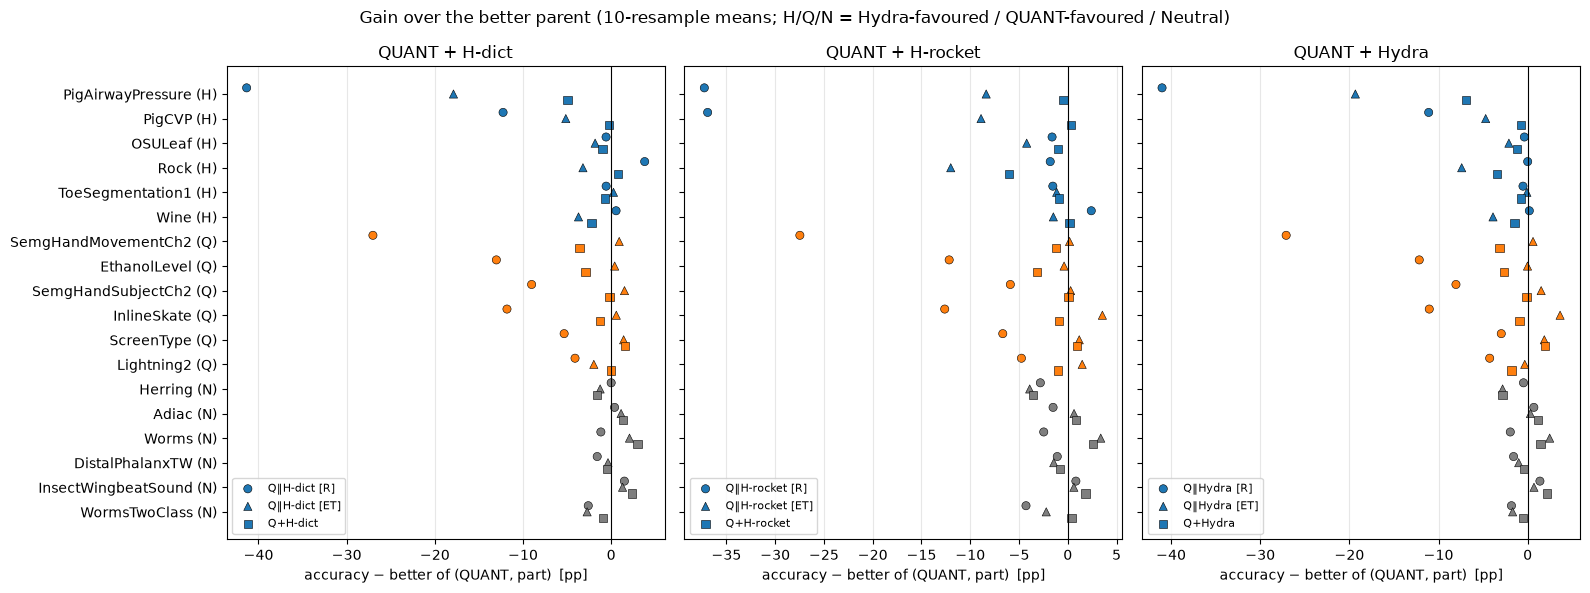

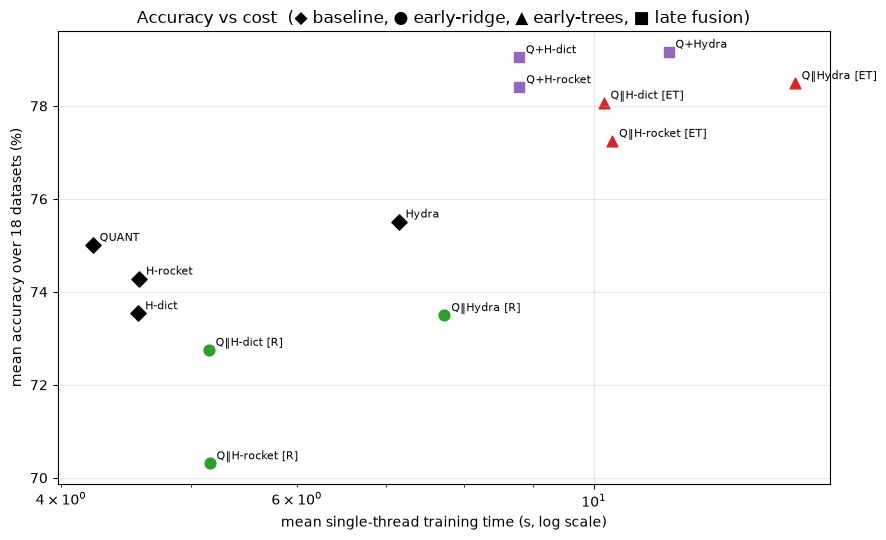

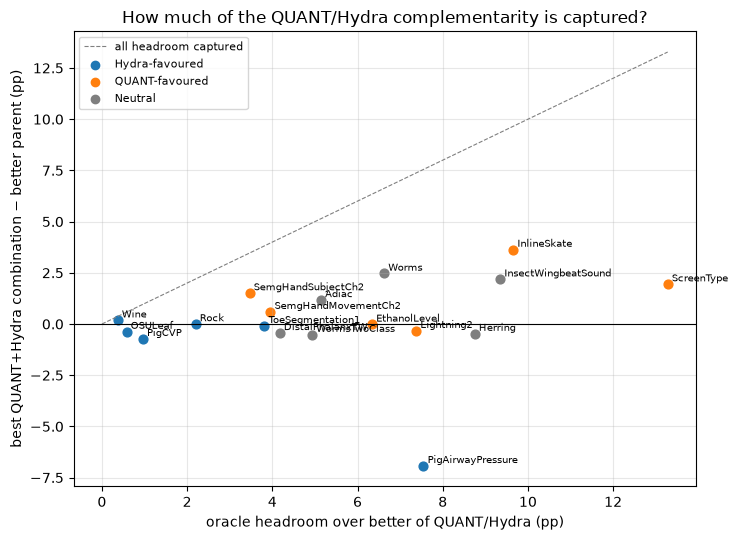

In [14]:
colors = {"Hydra-favoured": "tab:blue", "QUANT-favoured": "tab:orange", "Neutral": "tab:gray"}
markers = {"early (ridge)": "o", "early (trees)": "^", "late": "s"}
ylab = [f"{d} ({GROUP_OF[d][0]})" for d in DATASETS]

# (a) gain of each combination over the better parent, per dataset
fig, axes = plt.subplots(1, 3, figsize=(16, 6), sharey=True)
for ax, part in zip(axes, PARTS.values()):
    best_parent = mean_acc.loc[DATASETS, ["QUANT", part]].max(axis=1)
    for j, fusion in enumerate(markers):
        cfg = {"early (ridge)": f"Q‖{part} [R]", "early (trees)": f"Q‖{part} [ET]", "late": f"Q+{part}"}[fusion]
        d = (mean_acc.loc[DATASETS, cfg] - best_parent) * 100
        ax.scatter(d, np.arange(len(DATASETS)) + (j - 1) * 0.25, marker=markers[fusion], s=35,
                   c=[colors[GROUP_OF[x]] for x in DATASETS], edgecolors="black", linewidths=0.4, label=cfg)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"QUANT + {part}")
    ax.set_xlabel("accuracy − better of (QUANT, part)  [pp]")
    ax.grid(True, axis="x", alpha=0.3)
    ax.legend(fontsize=8, loc="lower left")
axes[0].set_yticks(np.arange(len(DATASETS)))
axes[0].set_yticklabels(ylab)
axes[0].invert_yaxis()
fig.suptitle("Gain over the better parent (10-resample means; H/Q/N = Hydra-favoured / QUANT-favoured / Neutral)")
fig.tight_layout()
fig.savefig(PLOT_DIR / "gain_over_better_parent.png", dpi=200)
plt.show()

# (b) accuracy vs training time
fig, ax = plt.subplots(figsize=(9, 5.5))
for cfg in CONFIGS:
    fusion = CONFIG_INFO[cfg][1]
    ax.scatter(cost.loc[cfg, "train_seconds"], cost.loc[cfg, "mean_acc_%"], s=60,
               marker=markers.get(fusion, "D"), color="black" if fusion == "baseline" else
               {"early (ridge)": "tab:green", "early (trees)": "tab:red", "late": "tab:purple"}[fusion])
    ax.annotate(cfg, (cost.loc[cfg, "train_seconds"], cost.loc[cfg, "mean_acc_%"]),
                textcoords="offset points", xytext=(5, 3), fontsize=8)
ax.set_xscale("log")
ax.set_xlabel("mean single-thread training time (s, log scale)")
ax.set_ylabel("mean accuracy over 18 datasets (%)")
ax.set_title("Accuracy vs cost  (◆ baseline, ● early-ridge, ▲ early-trees, ■ late fusion)")
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(PLOT_DIR / "accuracy_vs_train_time.png", dpi=200)
plt.show()

# (c) complementarity: oracle headroom vs gain actually obtained (QUANT + full Hydra)
c = comp[comp.hydra_part == "Hydra"].set_index("dataset")
fig, ax = plt.subplots(figsize=(7.5, 5.5))
x = (c["oracle"] - c["better_parent"]) * 100
y = (c["best_combination"] - c["better_parent"]) * 100
for d in DATASETS:
    ax.scatter(x[d], y[d], color=colors[GROUP_OF[d]], s=40)
    ax.annotate(d, (x[d], y[d]), fontsize=7, xytext=(3, 2), textcoords="offset points")
ax.plot([0, x.max()], [0, x.max()], ls="--", color="gray", lw=0.8, label="all headroom captured")
ax.axhline(0, color="black", lw=0.8)
for g, col in colors.items():
    ax.scatter([], [], color=col, label=g)
ax.set_xlabel("oracle headroom over better of QUANT/Hydra (pp)")
ax.set_ylabel("best QUANT+Hydra combination − better parent (pp)")
ax.set_title("How much of the QUANT/Hydra complementarity is captured?")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(PLOT_DIR / "complementarity.png", dpi=200)
plt.show()

### Cell 14 — Save summary table

In [15]:
summary = (runs.groupby(["dataset", "config"])
           .agg(group=("group", "first"), hydra_part=("hydra_part", "first"), fusion=("fusion", "first"),
                n_resamples=("accuracy", "size"), mean_accuracy=("accuracy", "mean"), std_accuracy=("accuracy", "std"),
                mean_macro_f1=("macro_f1", "mean"), n_features=("n_features", "mean"))
           .reset_index())
summary = summary.merge(  # isolated single-thread timings (resample 0)
    timing[["dataset", "config", "train_seconds", "test_seconds"]]
    .rename(columns={"train_seconds": "train_seconds_isolated", "test_seconds": "test_seconds_isolated"}),
    on=["dataset", "config"], how="left")
summary.to_csv(OUT_DIR / "quant_hydra_summary.csv", index=False)
print("Saved", OUT_DIR / "quant_hydra_summary.csv", "|", len(summary), "rows")

Saved c:\Users\User\Documents\hydra-time-series-project\results\Aarti\quant_hydra\quant_hydra_summary.csv | 234 rows


## Results and interpretation

**Run:** 18 datasets × 10 resamples × 13 configurations (2,340 results); cost from isolated single-thread runs on resample 0 of every dataset.

### 1. The baselines reproduce the published numbers
* **Hydra:** mean difference to the paper **+0.15 pp** (mean |diff| 0.70 pp), **18 / 18 datasets within expected variance**.
* **QUANT:** mean difference **−0.08 pp** (mean |diff| 0.83 pp), **18 / 18 within expected variance**.
* The published QUANT-vs-Hydra gaps that defined the groups are confirmed in sign and size for all 12 favoured datasets (e.g. SemgHandMovementCh2 +36.8 pp vs +36.5 pp published, PigCVP −28.3 vs −27.5). In the *neutral* group our gaps scatter by up to ±3 pp (Herring −3.3, Worms −3.1, WormsTwoClass +2.3): these have only 64–77 test cases, so "neutral" really means "no consistent winner".

So the combination results below are built on baselines that behave as published.

### 2. Overall, combining helps on average — by avoiding each model's failures, not by beating the better one
Mean accuracy over all 18 datasets: **Q+Hydra 79.2 %** (best mean rank, 4.8) and Q+H-dict 79.1 %, vs **Hydra 75.5 %** and **QUANT 75.0 %**. A late-fusion combination is ~+4 pp better than either single model *on average* (Q+Hydra vs Hydra: +3.7 pp, 11 wins / 7 losses, p = 0.17; vs QUANT: +4.2 pp, 11 / 7, p = 0.06) — a consistent direction, but not statistically significant over 18 datasets.

But against **the better of its two parents on each dataset** no combination wins overall (Q+Hydra −1.1 pp, 4 wins / 14 losses, p = 0.054). The average gain comes from robustness: QUANT collapses on the Hydra-favoured datasets and Hydra collapses on the QUANT-favoured ones, and a combination is never as bad as the weaker model.

| Group | Best single model | Best combination | Difference | Verdict |
|---|---|---|---|---|
| **Hydra-favoured** | Hydra 90.3 % | Q+Hydra 87.8 % | −2.4 pp (0 / 6, p = 0.031) | **no combination beats Hydra**; adding QUANT hurts |
| **QUANT-favoured** | QUANT 77.0 % | Q‖Hydra [ET] 78.2 % | **+1.2 pp** (4 / 2, p = 0.16); Q‖H-rocket [ET] +1.05 pp (5 / 1) | **trees on QUANT+Hydra features beat QUANT** |
| **Neutral** | Hydra 73.0 % | Q+Hydra 73.7 % | +0.7 pp; Q+H-dict +0.6 pp vs better parent (3 / 3) | small, not significant gain |

### 3. Which fusion works depends on which model is stronger — the stronger model's classifier must be in charge
* **Early fusion with trees** (`[ET]`) is the best option where QUANT is strong: ExtraTrees can pick up useful Hydra features (InlineSkate 58.7 → 62.3 %, Lightning2 77.7 → 79.2 %, SemgHandSubjectCh2 92.4 → 93.9 %), but where Hydra is strong trees cannot use Hydra's many sparse count features well (Hydra-favoured: 84.0 % vs Hydra 90.3 %).
* **Late fusion** (`+`) is the most *robust*: never more than ~2.4 pp below the better parent in any group, far above the weaker one, and best on the neutral group. Because one cannot know in advance which group a new dataset belongs to, late fusion is the safest default.
* **Early fusion with ridge** (`[R]`) is the worst option everywhere (−6.8 pp vs better parent overall, p = 0.002) and collapses on the 52-class Pig datasets (PigAirwayPressure 28–33 % vs Hydra 74 %). QUANT contributes more features than Hydra (e.g. 17,752 vs 8,192 on the Pig datasets, 25,203 vs 9,216 on Rock), and once standardised these dense features dominate the ridge penalty. The selected alpha also sits at the grid ceiling (1000) in **71–79 % of early-ridge runs** vs 62 % for Hydra alone, so the unreported alpha grid (see `aarti_hydra_reproduction_resamples.ipynb`) is an even tighter constraint here.

### 4. Dictionary half vs ROCKET half
* Alone, the halves behave as Hydra's design suggests: **H-dict** (hard counts) is better on the Hydra-favoured group (88.9 % vs 86.9 %), **H-rocket** (soft counts) on the QUANT-favoured group (63.9 % vs 59.6 %). Full Hydra beats both on average (75.5 % vs 73.5 / 74.3 %).
* **With QUANT, the dictionary half is enough:** Q+H-dict reaches 79.1 % vs 79.2 % for Q+Hydra (and improves on H-dict alone by +5.5 pp, 12 wins / 6 losses, p = 0.027 — the only combination-vs-its-Hydra-part gain significant over all 18 datasets), while its Hydra transform costs only **0.64×** the full Hydra transform. QUANT appears to supply much of the magnitude/distribution information the ROCKET-like half adds.

### 5. Complementarity exists but naive fusion captures little of it
QUANT and Hydra disagree on many test cases: on average ~28 % of test cases in the QUANT-favoured group, ~20 % in the Hydra-favoured group and ~15 % in the neutral group are classified correctly by exactly one of them, and the oracle (correct if either is right) is far above both, e.g. PigAirwayPressure: oracle 81.9 % vs Hydra 74.3 % vs best combination 67.4 %. Equal-weight fusion and simple concatenation recover only a small part of this headroom (and none of it on the Hydra-favoured group), which suggests that **weighting the two models per dataset** (e.g. by cross-validated accuracy, as in HIVE-COTE-style ensembles) is the natural next step.

### 6. Computational cost (isolated single-thread runs, mean over 18 datasets)
| Configuration | Train (s) | Test (s) | Train × Hydra | Test × Hydra | Mean acc. |
|---|---|---|---|---|---|
| QUANT | 4.22 | 0.71 | 0.59 | **0.07** | 75.0 % |
| Hydra | 7.15 | 9.89 | 1.00 | 1.00 | 75.5 % |
| H-dict / H-rocket | 4.57 | 6.37 | 0.64 | 0.64 | 73.5 / 74.3 % |
| Q‖Hydra [R] | 7.73 | 10.59 | 1.08 | 1.07 | 73.5 % |
| Q‖Hydra [ET] | 14.13 | 10.60 | 1.98 | 1.07 | 78.5 % |
| Q+Hydra | 11.37 | 10.60 | 1.59 | 1.07 | **79.2 %** |
| **Q+H-dict** | 8.79 | 7.08 | 1.23 | **0.72** | 79.1 % |

* QUANT is ~14× cheaper than Hydra at test time; Hydra's convolutions dominate inference cost in every combination.
* Computing only one Hydra half costs **0.6×** (not 0.5×) the full transform: the convolutions are shared work, only the max/min counting is halved.
* **Q+H-dict is the best accuracy/cost trade-off:** +3.5 pp mean accuracy over Hydra with *lower* test cost (0.72×) and 1.23× training cost.

### Caveats
* 10 resamples (the papers use 30); all configuration comparisons are paired on the same splits, and the comparison with the published means accounts for n = 10 vs 30.
* 6 datasets per group: the smallest possible Wilcoxon p is 0.031 and many comparisons are made, so individual p-values are indicative, not confirmatory.
* "Better parent" is chosen per dataset after the fact; the maximum of two noisy means is biased upwards, so this comparison is slightly unfavourable to the combinations.
* Timing is from one resample on one laptop (hybrid P/E-core CPU): ratios between configurations are meaningful, absolute seconds are not comparable with the papers' cluster timings.